In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/drive/MyDrive/Sample-Superstore.csv')
print("Размер таблицы:", df.shape)
print('Столбцы:')
print(df.columns.tolist())
print("\nИнформация о таблице:")
df.info()
print("\nПропуски:")
display(df.isna().sum().sort_values(ascending=False))
print("\nПолных дубликатов:", df.duplicated().sum())
display(df.describe())

Размер таблицы: (9994, 22)
Столбцы:
['csvbase_row_id', '\ufeffRow ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Информация о таблице:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   csvbase_row_id  9994 non-null   int64  
 1   ﻿Row ID         9994 non-null   int64  
 2   Order ID        9994 non-null   object 
 3   Order Date      9994 non-null   object 
 4   Ship Date       9994 non-null   object 
 5   Ship Mode       9994 non-null   object 
 6   Customer ID     9994 non-null   object 
 7   Customer Name   9994 non-null   object 
 8   Segment         9994 non-null   object 
 9   Country         9994 non-null   object 
 10  City 

,0
csvbase_row_id,0
﻿Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0



Полных дубликатов: 0


,csvbase_row_id,﻿Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [3]:
df =  df.copy()
df.columns = (df.columns.str.replace("\ufeff", "", regex = False).str.strip())
if "csvbase_row_id" in df.columns:
  df = df.drop(columns = ["csvbase_row_id"])
df["Order Date"] = pd.to_datetime(df["Order Date"], errors = "coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors = "coerce")
print("Размер таблицы", df.shape)
print("\nТипы данных:")
print(df.dtypes[["Order Date", "Ship Date", "Sales", "Profit"]])
print("Период заказов:", df["Order Date"].min(), "-", df["Order Date"].max())
display(df[['Sales', "Quantity", "Discount", "Profit"]].agg(['min', 'max', 'mean', 'median']).round(2))
print("Строк с отрицательными Sales:", (df["Sales"] < 0).sum())
print("Строк с отрицательным Profit:", (df["Profit"] < 0).sum())
print("Строк с нулевой или отрицательной Sales:",
      (df["Sales"] <= 0).sum())





Размер таблицы (9994, 21)

Типы данных:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
Sales                float64
Profit               float64
dtype: object
Период заказов: 2014-01-03 00:00:00 - 2017-12-30 00:00:00


,Sales,Quantity,Discount,Profit
min,0.44,1.00,0.00,-6599.98
max,22638.48,14.00,0.80,8399.98
mean,229.86,3.79,0.16,28.66
median,54.49,3.00,0.20,8.67


Строк с отрицательными Sales: 0
Строк с отрицательным Profit: 1871
Строк с нулевой или отрицательной Sales: 0


In [4]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product ID"].nunique()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else np.nan
)

kips = pd.DataFrame({
    "Показатель": [
        "Общая выручка",
        "Общая прибыль",
        "Количество заказов",
        "Количество клиентов",
        "Количество уникальных товаров",
        "Маржа прибыли, %"
    ],
    "Значение": [
        round(total_sales, 2),
        round(total_profit, 2),
        total_orders,
        total_customers,
        total_products,
        round(profit_margin, 2)
    ]
})
display(kips)

,Показатель,Значение
0,Общая выручка,2297200.86
1,Общая прибыль,286397.02
2,Количество заказов,5009.00
3,Количество клиентов,793.00
4,Количество уникальных товаров,1862.00
5,"Маржа прибыли, %",12.47


In [5]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=kips)

https://docs.google.com/spreadsheets/d/1RpF1b3wUscDfnL36ubV7m24aDn9erXQBY4r_sdt0REY/edit#gid=0


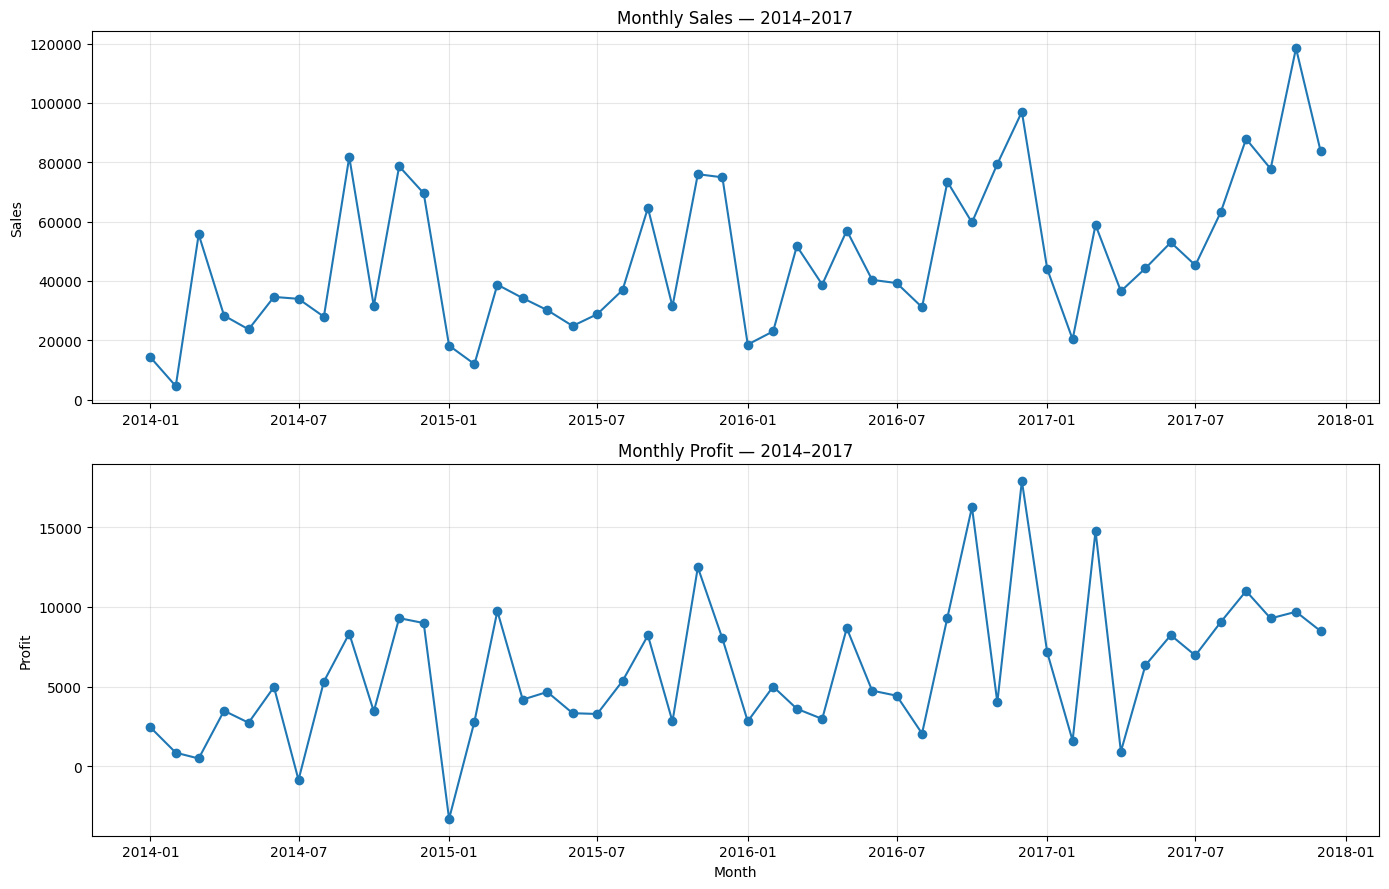

In [7]:
monthly = (df.groupby(df["Order Date"].dt.to_period("M")).agg(Sales = ("Sales", "sum"), Profit = ("Profit", "sum")).reset_index())
monthly["Order Date"] = monthly["Order Date"].dt.to_timestamp()
fig, axes = plt.subplots(2, 1, figsize = (14, 9))
axes[0].plot(monthly["Order Date"], monthly["Sales"], marker = "o")
axes[0].set_title("Monthly Sales — 2014–2017")
axes[0].set_ylabel("Sales")
axes[0].grid(True, alpha=0.3)

axes[1].plot(monthly["Order Date"], monthly["Profit"], marker="o")
axes[1].set_title("Monthly Profit — 2014–2017")
axes[1].set_ylabel("Profit")
axes[1].set_xlabel("Month")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
display(monthly.sort_values("Sales", ascending=False).head(5))
print("Самый прибыльный месяц:")
display(monthly.loc[[monthly["Profit"].idxmax()]])
print("Самый убыточный месяц:")
display(monthly.loc[[monthly["Profit"].idxmin()]])

,Order Date,Sales,Profit
46,2017-11-01,118447.8250,9690.1037
35,2016-12-01,96999.0430,17885.3093
44,2017-09-01,87866.6520,10991.5556
47,2017-12-01,83829.3188,8483.3468
8,2014-09-01,81777.3508,8328.0994


Самый прибыльный месяц:


,Order Date,Sales,Profit
35,2016-12-01,96999.043,17885.3093


Самый убыточный месяц:


,Order Date,Sales,Profit
12,2015-01-01,18174.0756,-3281.007


In [9]:
category_analysis = (df.groupby("Category").agg(Sales=("Sales", "sum"),Profit=("Profit", "sum"),
                                                Quantity=("Quantity", "sum")).reset_index())

category_analysis["Profit Margin, %"] = (category_analysis["Profit"] / category_analysis["Sales"] * 100).round(2)

category_analysis = category_analysis.sort_values("Profit", ascending=False)

display(category_analysis.round(2))

,Category,Sales,Profit,Quantity,"Profit Margin, %"
2,Technology,836154.03,145454.95,6939,17.40
1,Office Supplies,719047.03,122490.80,22906,17.04
0,Furniture,741999.80,18451.27,8028,2.49


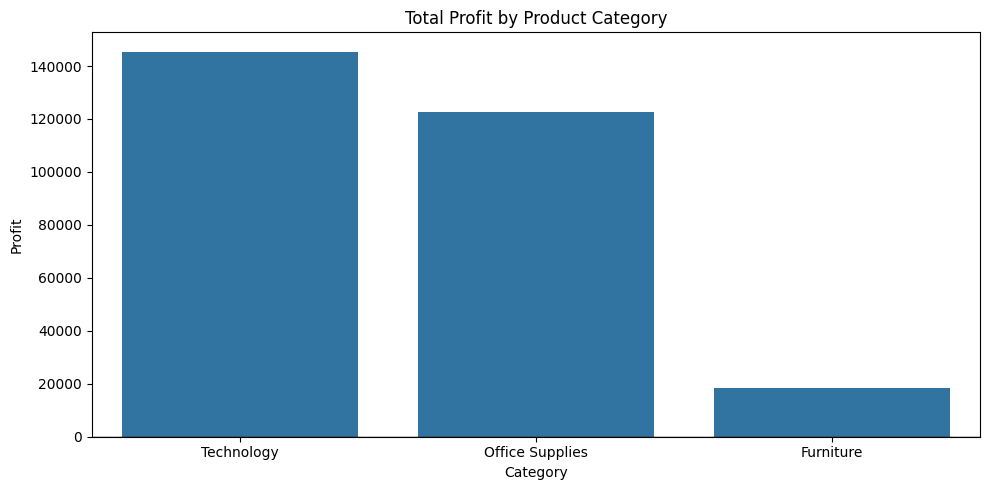

In [10]:
plt.figure(figsize = (10,5))
sns.barplot(data=category_analysis, x="Category", y="Profit")

plt.title("Total Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.axhline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

In [11]:
subcategory_analysis = (df.groupby(["Category", "Sub-Category"]).agg(Sales = ("Sales", "sum"), Profit=("Profit", "sum"),
                                                Quantity=("Quantity", "sum")).reset_index().sort_values("Profit"))
display(subcategory_analysis, round(2))


,Category,Sub-Category,Sales,Profit,Quantity
3,Furniture,Tables,206965.5320,-17725.4811,1241
0,Furniture,Bookcases,114879.9963,-3472.5560,868
12,Office Supplies,Supplies,46673.5380,-1189.0995,647
8,Office Supplies,Fasteners,3024.2800,949.5182,914
15,Technology,Machines,189238.6310,3384.7569,440
9,Office Supplies,Labels,12486.3120,5546.2540,1400
5,Office Supplies,Art,27118.7920,6527.7870,3000
7,Office Supplies,Envelopes,16476.4020,6964.1767,906
2,Furniture,Furnishings,91705.1640,13059.1436,3563
4,Office Supplies,Appliances,107532.1610,18138.0054,1729


2

In [12]:
subcategory_analysis = (df.groupby(["Category", "Sub-Category"]).agg(Sales=("Sales", "sum"),Profit=("Profit", "sum"),
                                                                     Quantity=("Quantity", "sum"),Avg_Discount=("Discount", "mean"))
.reset_index())
subcategory_analysis["Profit_Margin_%"] = (subcategory_analysis["Profit"] / subcategory_analysis["Sales"] * 100).round(2)
subcategory_analysis["Avg_Discount"] = (subcategory_analysis["Avg_Discount"] * 100).round(2)
display(subcategory_analysis.sort_values("Profit").round(2))

,Category,Sub-Category,Sales,Profit,Quantity,Avg_Discount,Profit_Margin_%
3,Furniture,Tables,206965.53,-17725.48,1241,26.13,-8.56
0,Furniture,Bookcases,114880.00,-3472.56,868,21.11,-3.02
12,Office Supplies,Supplies,46673.54,-1189.10,647,7.68,-2.55
8,Office Supplies,Fasteners,3024.28,949.52,914,8.20,31.40
15,Technology,Machines,189238.63,3384.76,440,30.61,1.79
9,Office Supplies,Labels,12486.31,5546.25,1400,6.87,44.42
5,Office Supplies,Art,27118.79,6527.79,3000,7.49,24.07
7,Office Supplies,Envelopes,16476.40,6964.18,906,8.03,42.27
2,Furniture,Furnishings,91705.16,13059.14,3563,13.83,14.24
4,Office Supplies,Appliances,107532.16,18138.01,1729,16.65,16.87


In [13]:
discount_analysis = (df.groupby("Discount").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                                Orders=("Order ID", "nunique"), Transactions=("Sales", "count"))
.reset_index())
discount_analysis["Profit_Margin_%"] = (discount_analysis["Profit"] / discount_analysis["Sales"] * 100)
discount_analysis["Discount_%"] = (discount_analysis["Discount"] * 100)

display(discount_analysis.round(2))

,Discount,Sales,Profit,Orders,Transactions,Profit_Margin_%,Discount_%
0,0.00,1087908.47,320987.60,2644,4798,29.51,0.0
1,0.10,54369.35,9029.18,89,94,16.61,10.0
2,0.15,27558.52,1418.99,51,52,5.15,15.0
3,0.20,764594.37,90337.31,2407,3657,11.82,20.0
4,0.30,103226.66,-10369.28,211,227,-10.05,30.0
5,0.32,14493.46,-2391.14,27,27,-16.50,32.0
6,0.40,116417.78,-23057.05,185,206,-19.81,40.0
7,0.45,5484.97,-2493.11,10,11,-45.45,45.0
8,0.50,58918.54,-20506.43,64,66,-34.80,50.0
9,0.60,6644.70,-5944.66,127,138,-89.46,60.0


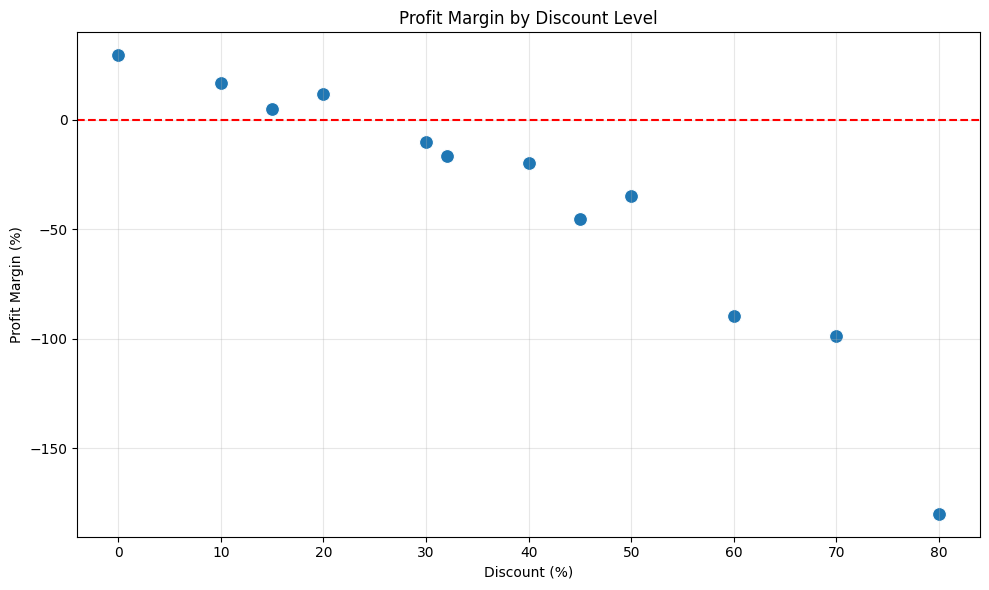

In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=discount_analysis, x="Discount_%", y="Profit_Margin_%", s=100)
plt.axhline(y=0, color="red", linestyle="--")

plt.title("Profit Margin by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
category_discount = (df.groupby(["Category", "Discount"]).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                                              Line_Items=("Sales", "count"))
.reset_index())
category_discount["Profit_Margin_%"] = (category_discount["Profit"] / category_discount["Sales"] * 100)

category_discount["Discount_%"] = (category_discount["Discount"] * 100)

display(category_discount.round(2))

,Category,Discount,Sales,Profit,Line_Items,Profit_Margin_%,Discount_%
0,Furniture,0.00,256025.27,58133.08,836,22.71,0.0
1,Furniture,0.10,46634.25,7111.01,76,15.25,10.0
2,Furniture,0.15,27558.52,1418.99,52,5.15,15.0
3,Furniture,0.20,216631.02,6265.95,615,2.89,20.0
4,Furniture,0.30,99470.35,-10695.32,222,-10.75,30.0
5,Furniture,0.32,14493.46,-2391.14,27,-16.50,32.0
6,Furniture,0.40,45614.41,-16187.40,75,-35.49,40.0
7,Furniture,0.45,5484.97,-2493.11,11,-45.45,45.0
8,Furniture,0.50,20983.47,-12871.20,54,-61.34,50.0
9,Furniture,0.60,6644.70,-5944.66,138,-89.46,60.0


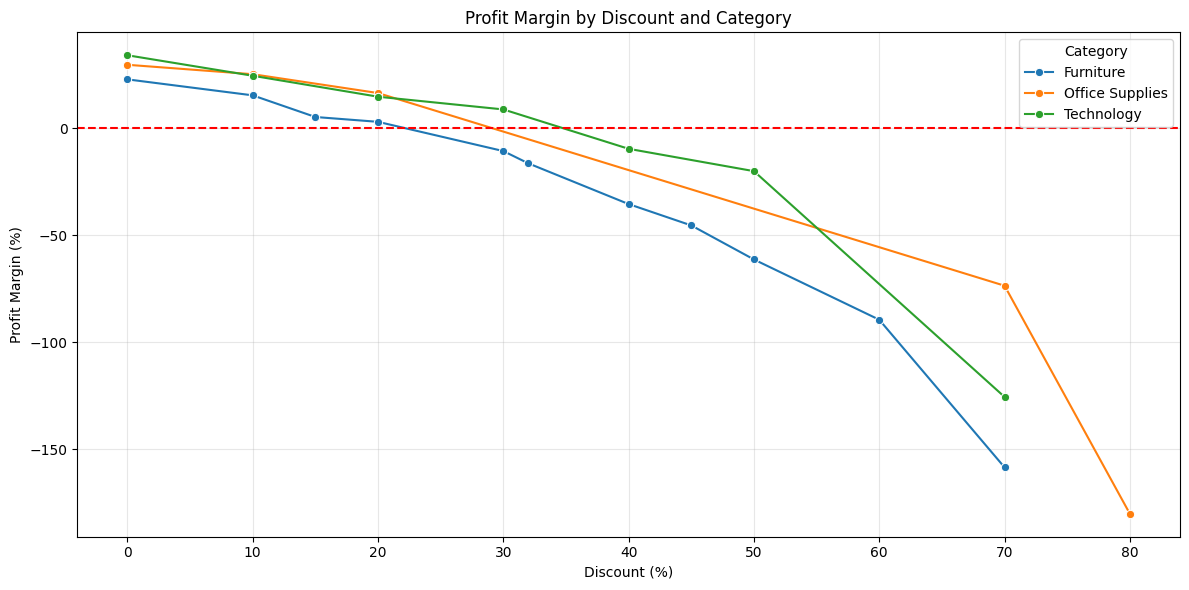

In [16]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=category_discount,
    x="Discount_%",
    y="Profit_Margin_%",
    hue="Category",
    marker="o",
    estimator=None)

plt.axhline(0, color="red", linestyle="--")
plt.title("Profit Margin by Discount and Category")
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
losses = df[df["Profit"] < 0].copy()
losses["Loss_Amount"] = -losses["Profit"]
losses["Discount_Group"] = np.where(
    losses["Discount"] >= 0.3,
    "30% and higher",
    "Below 30%")
loss_summary = (losses.groupby("Discount_Group").agg(
        Total_Loss=("Loss_Amount", "sum"),
        Loss_Rows=("Loss_Amount", "count"))
.reset_index())
loss_summary["Loss_Share_%"] = (loss_summary["Total_Loss"] / loss_summary["Total_Loss"].sum() * 100)
display(loss_summary.round(2))

,Discount_Group,Total_Loss,Loss_Rows,Loss_Share_%
0,30% and higher,138515.24,1348,88.72
1,Below 30%,17616.04,523,11.28


In [6]:
import sqlite3
conn = sqlite3.connect(":memory:")
df.to_sql("sales", conn, if_exists = "replace", index = False)

9994

In [7]:
query = """
SELECT
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit,
    COUNT(DISTINCT "Order ID") AS total_orders,
    COUNT(DISTINCT "Customer ID") AS total_customers,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS profit_margin
FROM sales;
"""

sql_kpis = pd.read_sql_query(query, conn)

display(sql_kpis)

,total_sales,total_profit,total_orders,total_customers,profit_margin
0,2297200.86,286397.02,5009,793,12.47


In [8]:
query = """
SELECT
    Category,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    SUM(Quantity) AS Total_Quantity,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM sales
GROUP BY Category
ORDER BY Total_Profit DESC;
"""

category_sql = pd.read_sql_query(query, conn)

display(category_sql)

,Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Technology,836154.03,145454.95,6939,17.40
1,Office Supplies,719047.03,122490.80,22906,17.04
2,Furniture,741999.80,18451.27,8028,2.49


In [9]:
query = """
SELECT
    Category,
    "Sub-Category",
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM sales
GROUP BY Category, "Sub-Category"
HAVING SUM(Profit) < 0
ORDER BY Total_Profit ASC;
"""

loss_categories_sql = pd.read_sql_query(query, conn)

display(loss_categories_sql)

,Category,Sub-Category,Total_Sales,Total_Profit
0,Furniture,Tables,206965.53,-17725.48
1,Furniture,Bookcases,114880.00,-3472.56
2,Office Supplies,Supplies,46673.54,-1189.10


In [16]:
query = """
SELECT
    Category,
    "Sub-Category",
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit
FROM sales
WHERE Category = 'Furniture'
GROUP BY Category, "Sub-Category"
HAVING SUM(Profit) < 0
ORDER BY Total_Profit ASC;
"""

loss_categories_sql = pd.read_sql_query(query, conn)

display(loss_categories_sql)

,Category,Sub-Category,Total_Sales,Total_Profit
0,Furniture,Tables,206965.53,-17725.48
1,Furniture,Bookcases,114880.00,-3472.56


In [17]:
query = """
SELECT
    CASE
        WHEN Discount >= 0.3 THEN '30% and higher'
        ELSE 'Below 30%'
    END AS Discount_Group,

    ROUND(-SUM(Profit), 2) AS Total_Loss,

    COUNT(*) AS Loss_Rows

FROM sales
WHERE Profit < 0

GROUP BY
    CASE
        WHEN Discount >= 0.3 THEN '30% and higher'
        ELSE 'Below 30%'
    END

ORDER BY Total_Loss DESC;
"""

sql_losses = pd.read_sql_query(query, conn)

sql_losses["Loss_Share_%"] = (
    sql_losses["Total_Loss"]
    / sql_losses["Total_Loss"].sum() * 100
).round(2)

display(sql_losses)

,Discount_Group,Total_Loss,Loss_Rows,Loss_Share_%
0,30% and higher,138515.24,1348,88.72
1,Below 30%,17616.04,523,11.28
